# VAD Pipeline Final Testing

### Important notes 

The exported model is fsmn-vad coming from [FUN-ASR](https://huggingface.co/funasr/fsmn-vad).

in `FUN-ASR` the preprocessing of waveform consists of four phases:
1. Windowing/Framing (each frame is 25ms, shifted by 10ms)
2. Convert to log-mel scale by:
  - applying `hamming` window for each frame
  - applying `fft` for each frame
  - using `kaldi.fbank` with 80 mel bank filters
3. applying `LFR` (low frame rate) preprocessing (stacking 5 next frames to create bigger frame)
4. applying `CMVN` (cepstral mean and variance normalization) with precomputed weights 

The original **preprocessing** pipeline might be found in the file `wav_frontend.py` in the `funasr/frontends` directory. Note that the preprocessing uses `FrontendWavOnline` class, not the `FrontendWav` class.

I have made some small internal changes, but overall preprocessing pipeline is the same. 

The final exported model takes steps `2-4` inside the model black-box, so here we focus only on the step 1.

After some tests, I have decided that **postprocessing** from fsmn-vad is unnecessarily compleceted, therefore i have used something similair to what is used in [silero-vad](https://github.com/snakers4/silero-vad/blob/master/src/silero_vad/utils_vad.py). 

## This file serves as a testing playground and self-contained tool for result-comparison of exported model with silero-vad.

### Imports

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Dict


### Choose audio-file

In [ ]:
audio_path = "test-processed_audio.wav"

### Prepare Exported Vad

In [3]:
from vad_pipeline import VADPipeline, waveform_from_audio
vad = VADPipeline()

W0912 17:16:00.972000 19961 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Program methods: {'forward'}


### Prepare Silero Vad for result comparison

In [4]:
SAMPLING_RATE_SILERO = 16000
silero_model, utils = torch.hub.load(repo_or_dir='snakers4/silero-vad',
                                model='silero_vad',
                                force_reload=False,
                                onnx=False)
(get_speech_timestamps,
 save_audio,
read_audio,
VADIterator,
collect_chunks) = utils

Using cache found in /Users/filipzielinski/.cache/torch/hub/snakers4_silero-vad_master


### Util function for drawing plots to compare results

In [5]:
def draw_plot(audio_path: str,
                             exported_vad_segments: List[Dict[str, int]],
                             silero_vad_segments: List[Dict[str, int]]):
    waveform = waveform_from_audio(audio_path)
    """
    Plots the audio waveform, exported VAD segments, and Silero VAD segments
    on three vertically aligned subplots.

    Args:
        waveform (torch.Tensor): The audio waveform tensor, shape [1, num_samples].
        exported_vad_segments (List[Dict[str, int]]): Segments from your VAD model.
                                                      Each dict must have 'start' and 'end' sample indices.
        silero_vad_segments (List[Dict[str, int]]): Segments from the Silero VAD model.
                                                    Each dict must have 'start' and 'end' sample indices.
    """
    # --- 1. Data Preparation ---
    waveform_np = waveform.squeeze().numpy()
    num_samples = len(waveform_np)
    time_axis = np.arange(num_samples)

    # --- 2. Create Binary Signals from Speech Segments ---
    exported_vad_signal = np.zeros(num_samples)
    for segment in exported_vad_segments:
        start_sample = segment.get('start')
        end_sample = segment.get('end')
        if start_sample is not None and end_sample is not None:
            exported_vad_signal[start_sample:end_sample] = 1

    silero_vad_signal = np.zeros(num_samples)
    for segment in silero_vad_segments:
        start_sample = segment.get('start')
        end_sample = segment.get('end')
        if start_sample is not None and end_sample is not None:
            silero_vad_signal[start_sample:end_sample] = 1

    # --- 3. Plotting ---
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(15, 9))
    fig.suptitle("Voice Activity Detection Comparison", fontsize=16)

    # Plot 1: Audio Waveform
    ax1.plot(time_axis, waveform_np, color='dodgerblue', linewidth=1)
    ax1.set_title("Audio Waveform")
    ax1.set_ylabel("Amplitude")
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.margins(x=0)

    # Plot 2: Exported VAD Segments
    ax2.fill_between(time_axis, exported_vad_signal, color='crimson', alpha=0.8, step='post')
    ax2.set_title("Exported VAD Segments")
    ax2.set_ylabel("Speech Activity")
    ax2.set_yticks([0, 1])
    ax2.set_yticklabels(['Silence', 'Speech'])
    ax2.set_ylim([-0.1, 1.1])
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.margins(x=0)

    # Plot 3: Silero VAD Speech Segments
    ax3.fill_between(time_axis, silero_vad_signal, color='mediumseagreen', alpha=0.8, step='post')
    ax3.set_title("Silero VAD Speech Segments")
    ax3.set_xlabel("Time (samples)")
    ax3.set_ylabel("Speech Activity")
    ax3.set_yticks([0, 1])
    ax3.set_yticklabels(['Silence', 'Speech'])
    ax3.set_ylim([-0.1, 1.1])
    ax3.grid(True, linestyle='--', alpha=0.6)
    ax3.margins(x=0)

    # Improve layout and display the plot
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [6]:
def compare_result(audio_path):
  # run exported fsmn
  fsmn_res = vad.run(audio_path)
  print(fsmn_res)  
  
  # run silero
  silero_wav = read_audio(audio_path, sampling_rate=SAMPLING_RATE_SILERO)
  silero_res = get_speech_timestamps(silero_wav, silero_model, sampling_rate=SAMPLING_RATE_SILERO)
  print(silero_res)
  
  draw_plot(audio_path, fsmn_res, silero_res)

[{'start': 0, 'end': 37440}, {'start': 42240, 'end': 75680}, {'start': 77600, 'end': 111200}, {'start': 148640, 'end': 159840}, {'start': 160000, 'end': 173280}]
[{'start': 32, 'end': 32736}, {'start': 43040, 'end': 77792}, {'start': 79392, 'end': 109536}, {'start': 149024, 'end': 164320}]


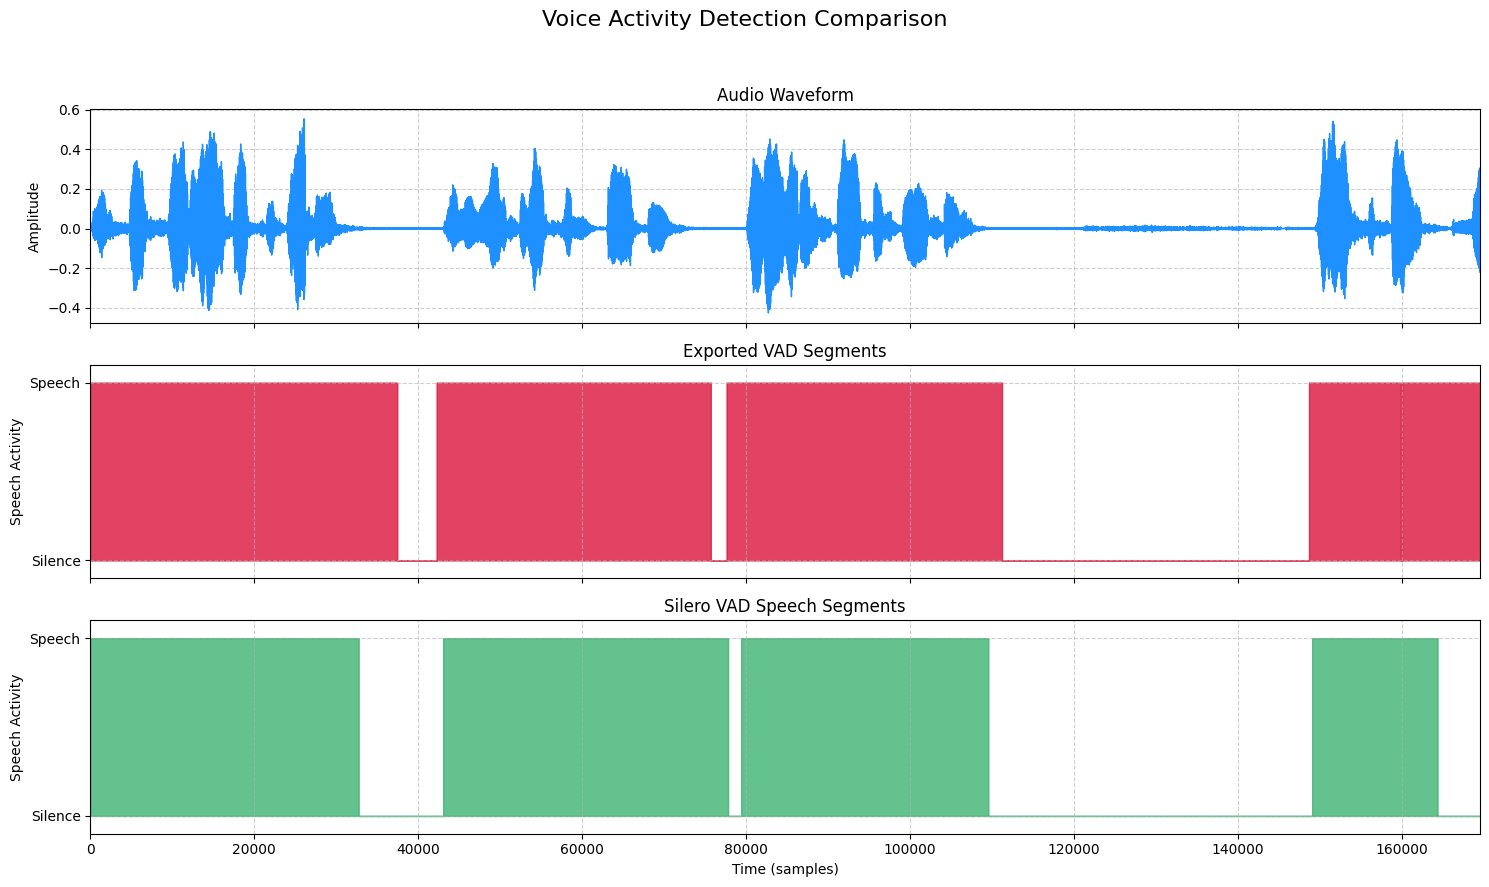

In [ ]:
audio_path = "example_audio/audio-11s.wav"
compare_result(audio_path)